# Representations

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['figure.dpi'] = 150

In [2]:
# Check available hardware
import torch
if torch.cuda.is_available():
    print(f'GPU is available, using GPU {torch.cuda.get_device_name(0)}')
    device = torch.device('cuda')
elif torch.mps.is_available():
    print(f'Apple Metal Performance Shaders framework is available, using {torch.device("mps")}')
    device = torch.device('mps')
else:
    print(f'Hardware acceleration not available, using CPU')
    device = torch.device('cpu')

GPU is available, using GPU Tesla T4


## Dataset: MNIST

In [3]:
import torch
import torchvision
from torchvision.transforms import v2

transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)
])
mnist = torchvision.datasets.MNIST(root='~/scr10/', train=True, transform=transform, download=True)
mnist_test = torchvision.datasets.MNIST(root='~/scr10/', train=False, transform=transform, download=False)
from torch.utils.data import random_split
mnist_train, mnist_val = random_split(mnist, [0.8, 0.2])
print('Training dataset has length', len(mnist_train))
print('Training dataset has length', len(mnist_val))
print('Training dataset has length', len(mnist_test))

Training dataset has length 48000
Training dataset has length 12000
Training dataset has length 10000


In [4]:
x, y = mnist_train[0]
print('Input has shape', x.shape, 'and the output is', y)

Input has shape torch.Size([1, 28, 28]) and the output is 6


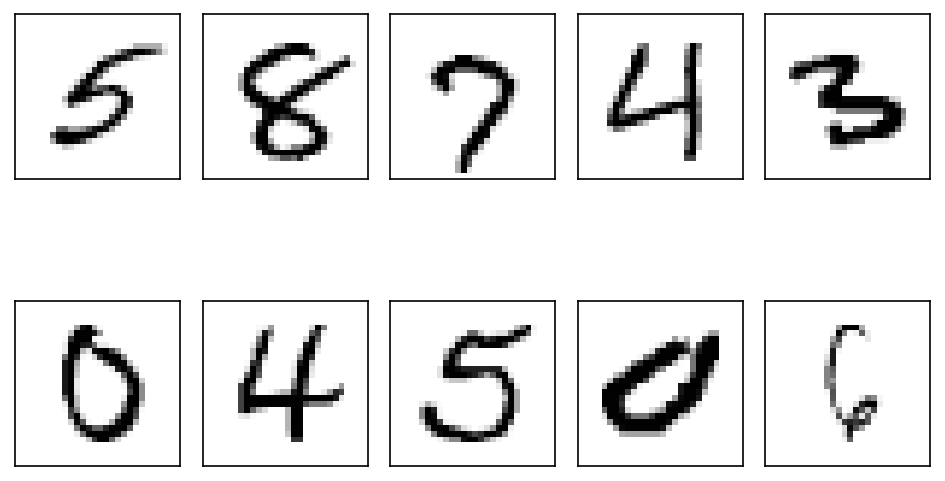

In [5]:
fig, ax = plt.subplots(2, 5, sharex=True, sharey=True)
ax = ax.flatten()
for ii in range(10):
    x, y = mnist_train[np.random.choice(len(mnist_train))]
    ax[ii].imshow(x.squeeze(), cmap='Greys')
    ax[ii].set(xticks=[], yticks=[])
plt.tight_layout()

## Supervised CNN

In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class SupervisedCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding='same'),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 32, kernel_size=3, padding='same'),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.fc1 = nn.Linear(32*7*7, 4)
        self.fc2 = nn.Linear(4, 10)

    def forward(self, x):
        x = self.cnn(x)
        x = x.reshape([x.shape[0], -1])

        # Get next-to-last layer features as representations
        z = self.fc1(x)
        z = F.relu(z)

        y = self.fc2(z)

        return y, z

model = SupervisedCNN()
y, z = model(x[None])
print(f'Model transforms input from size {x[None].shape} into prediction of size {y.shape} and representation of size {z.shape}')
model

Model transforms input from size torch.Size([1, 1, 28, 28]) into prediction of size torch.Size([1, 10]) and representation of size torch.Size([1, 4])


SupervisedCNN(
  (cnn): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc1): Linear(in_features=1568, out_features=4, bias=True)
  (fc2): Linear(in_features=4, out_features=10, bias=True)
)

In [7]:
from tqdm.notebook import tqdm, trange
from torch.utils.data import DataLoader

def train_supervised(model, loss_fn, optimizer, train_dataset, val_dataset, 
                     batch_size=32, num_epochs=50, num_workers=2, device=device):
    # Send model to correct hardware device
    model = model.to(device)

    # Create dataloaders for train/validation
    train_loader = DataLoader(train_dataset, batch_size=batch_size, num_workers=num_workers, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, num_workers=num_workers, shuffle=False)

    train_loss, train_acc = [], []
    val_loss, val_acc = [], []
    
    for epoch in range(num_epochs):
        train_loss_ = 0.
        train_acc_ = 0.
        model.train()
        for x, y, in tqdm(train_loader, leave=False):
            # Send x, y to GPU/TPU/etc.
            x = x.to(device)
            y = y.to(device)

            # Make a prediction, compute the loss
            y_pred, z_pred = model(x)
            loss = loss_fn(y_pred, y)

            # Backpropagate gradients, apply weight updates, reset gradients
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

            # Logging
            train_loss_ += loss.item() * x.shape[0]
            train_acc_  += (torch.argmax(y_pred, dim=1) == y).float().sum().item()

        train_loss.append(train_loss_ / len(train_dataset))
        train_acc.append(train_acc_ / len(train_dataset))

        val_loss_ = 0.
        val_acc_ = 0.
        model.eval()
        with torch.no_grad():
            for x, y, in tqdm(val_loader, leave=False):
                # Send x, y to GPU/TPU/etc.
                x = x.to(device)
                y = y.to(device)
    
                # Make a prediction, compute the loss
                y_pred, z_pred = model(x)
                loss = loss_fn(y_pred, y)
        
                # Logging
                val_loss_ += loss.item() * x.shape[0]
                val_acc_  += (torch.argmax(y_pred, dim=1) == y).float().sum().item()

            val_loss.append(val_loss_ / len(val_dataset))
            val_acc.append(val_acc_ / len(val_dataset))

        print(f'Epoch {epoch+1} | '
              f'Train loss { train_loss[-1]:.3f} | '
              f'Train acc { train_acc[-1]:.3f} | '
              f'Val loss { val_loss[-1]:.3f} | '
              f'Val acc { val_acc[-1]:.3f}'
        )

    return model, (train_loss, train_acc, val_loss, val_acc)

model = SupervisedCNN()
loss = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
model, model_stats = train_supervised(
    model, 
    loss, 
    optimizer, 
    mnist_train, 
    mnist_val, 
    num_epochs=10,
    batch_size=64,
    num_workers=4,
)

  0%|          | 0/750 [00:00<?, ?it/s]

  0%|          | 0/188 [00:00<?, ?it/s]

Epoch 1 | Train loss 1.358 | Train acc 0.475 | Val loss 1.080 | Val acc 0.600


  0%|          | 0/750 [00:00<?, ?it/s]

  0%|          | 0/188 [00:00<?, ?it/s]

Epoch 2 | Train loss 0.965 | Train acc 0.660 | Val loss 0.868 | Val acc 0.722


... (20 outputs left out)

Epoch 9 | Train loss 0.464 | Train acc 0.881 | Val loss 0.502 | Val acc 0.870


  0%|          | 0/750 [00:00<?, ?it/s]

  0%|          | 0/188 [00:00<?, ?it/s]

Epoch 10 | Train loss 0.440 | Train acc 0.886 | Val loss 0.496 | Val acc 0.873


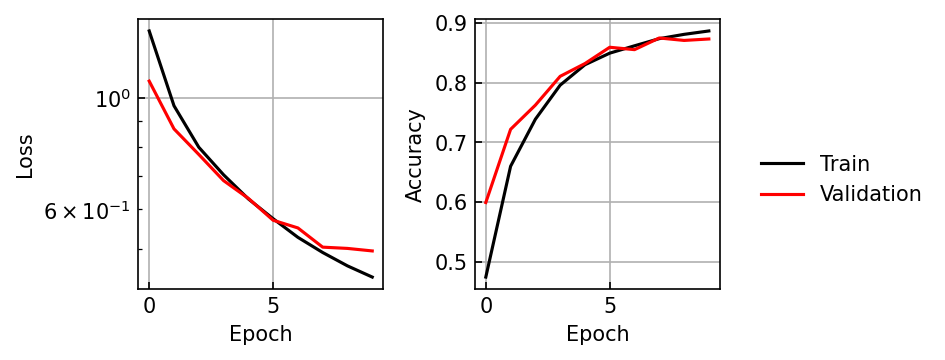

In [8]:
fig, ax = plt.subplots(1, 2, sharex=True, figsize=(5, 2.5))

train_loss, train_acc, val_loss, val_acc = model_stats
ax[0].plot(train_loss, color='black', label='Train')
ax[0].plot(val_loss, color='red', label='Validation')
ax[0].set(xlabel='Epoch', ylabel='Loss', yscale='log')

ax[1].plot(train_acc, color='black', label='Train')
ax[1].plot(val_acc, color='red', label='Validation')
ax[1].set(xlabel='Epoch', ylabel='Accuracy')

fig.legend(*ax[1].get_legend_handles_labels(), 
           loc='center left', bbox_to_anchor=[1, 0.5], framealpha=0)

plt.tight_layout()

### Inference

In [9]:
from sklearn.metrics import accuracy_score
# Inference
model.eval()
test_loader = DataLoader(mnist_test, batch_size=128, shuffle=False)

y_true = []
y_pred = []
z_pred = []

with torch.no_grad():
    test_correct_ = 0.
    for xb, yb in tqdm(test_loader,leave=False):
        xb = xb.to(device)
        yb = yb.to(device)
        yp, zp = model(xb)

        y_true.append(yb.cpu().numpy())
        y_pred.append(yp.cpu().numpy())
        z_pred.append(zp.cpu().numpy())

y_true = np.concatenate(y_true)
y_pred = np.concatenate(y_pred)
z_pred = np.concatenate(z_pred)

test_acc = accuracy_score(y_true, np.argmax(y_pred, axis=1))
print(f"Test accuracy: {test_acc:.3f}")

  0%|          | 0/79 [00:00<?, ?it/s]

Test accuracy: 0.877


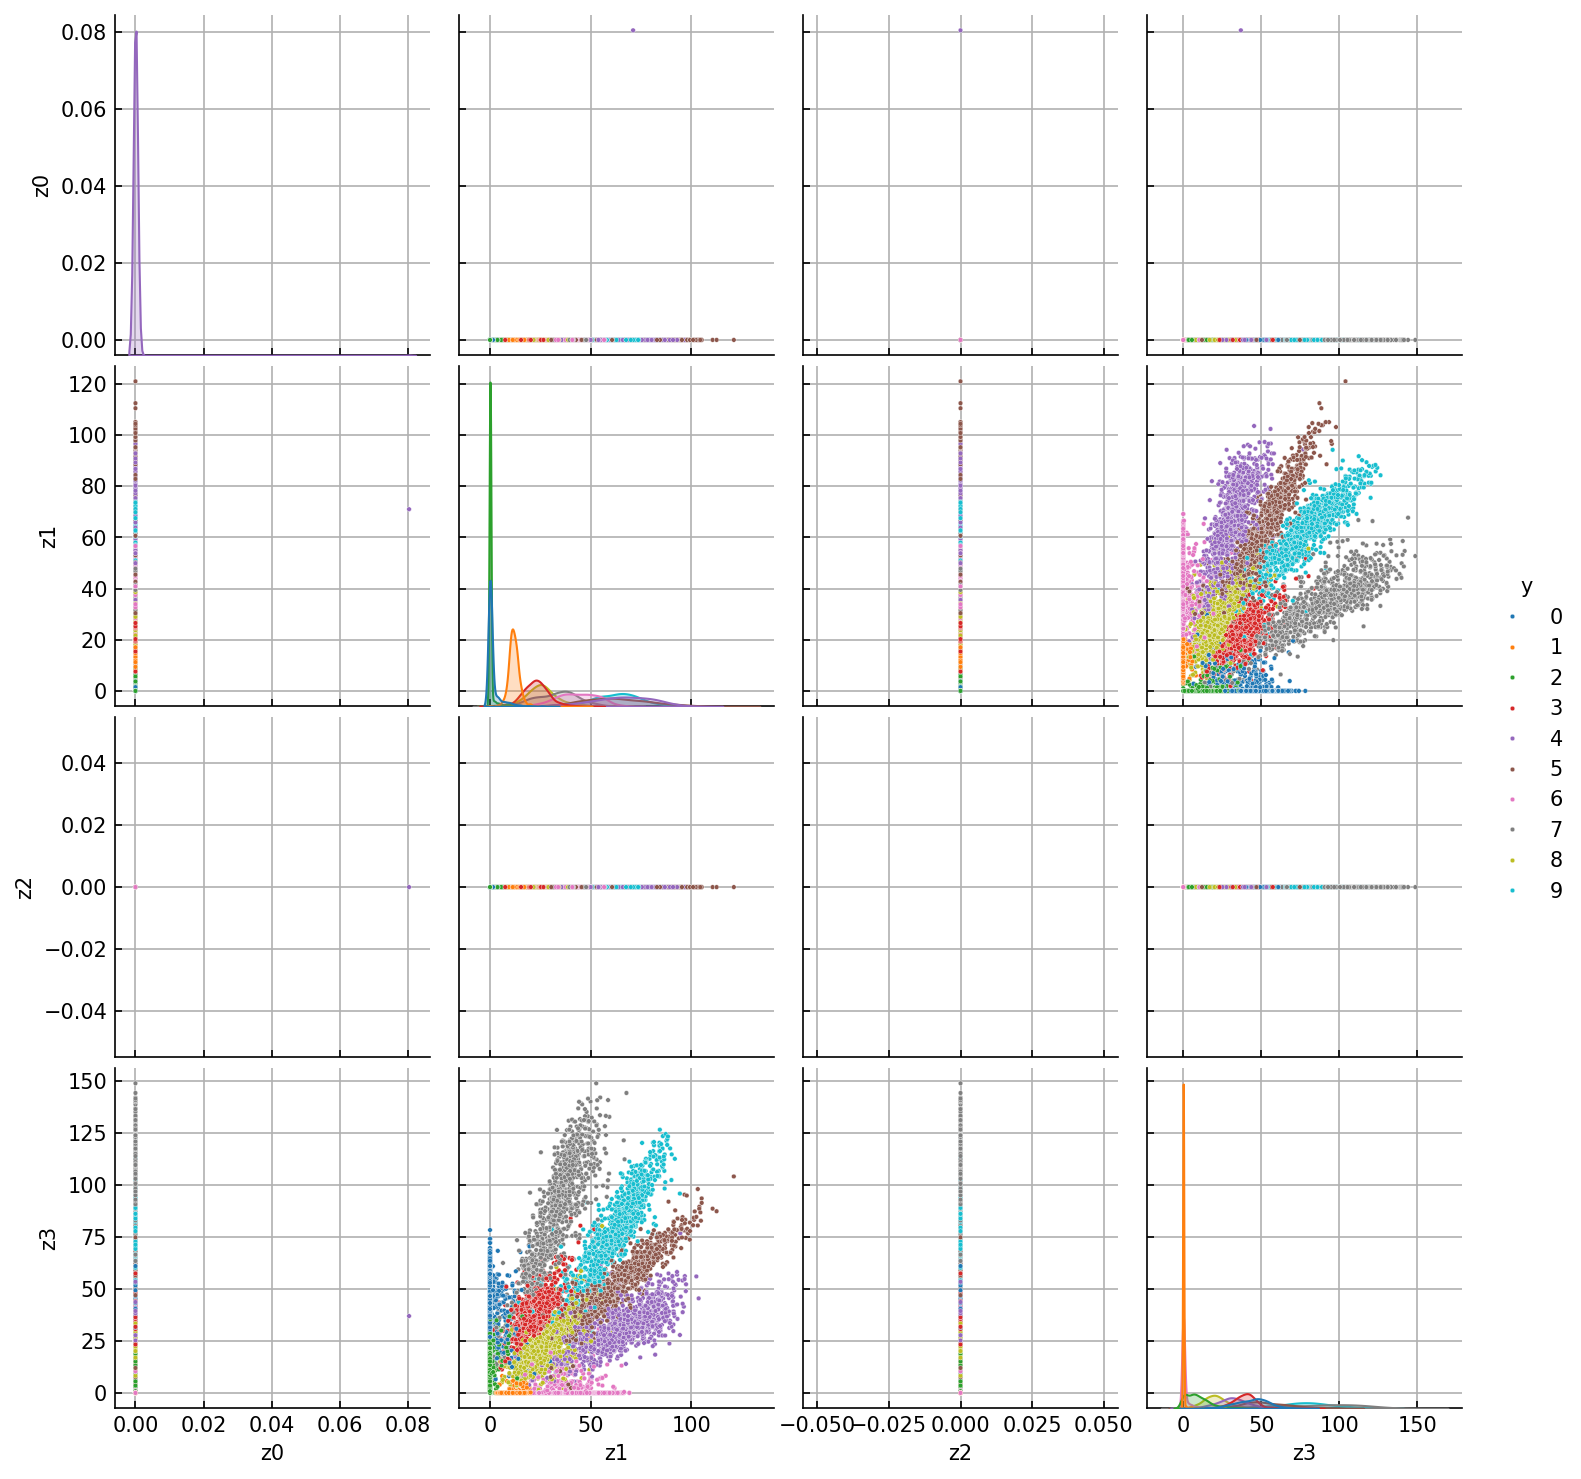

In [10]:
import seaborn as sns

df = pd.DataFrame({
    'z0': z_pred[:, 0],
    'z1': z_pred[:, 1],
    'z2': z_pred[:, 2],
    'z3': z_pred[:, 3],
    'y': y_true
})

sns.pairplot(df, hue='y', palette='tab10', plot_kws={'s': 5})

[Text(0.5, 0, 't-SNE 1'), Text(0, 0.5, 't-SNE 2')]

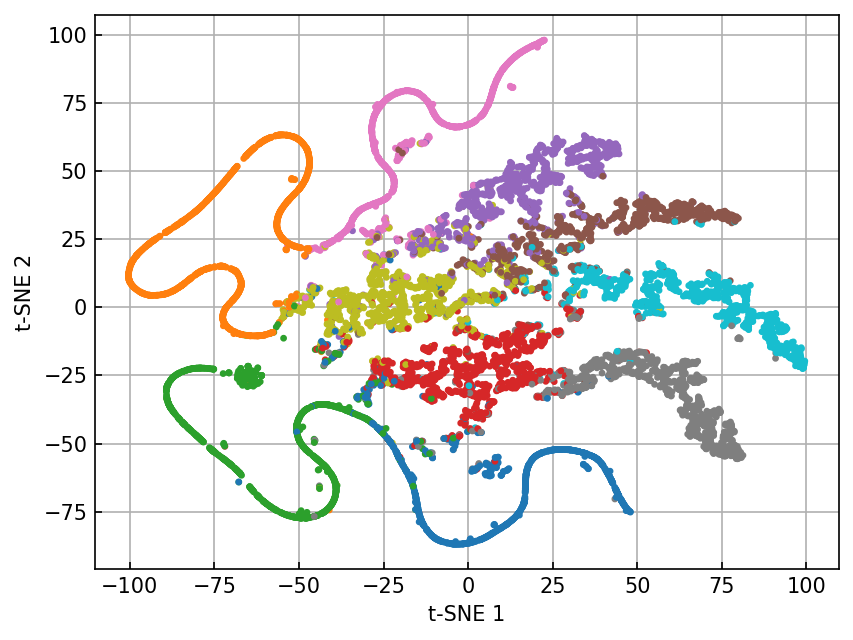

In [11]:
from sklearn.manifold import TSNE

viz = TSNE(n_components=2)
z_2d = viz.fit_transform(z_pred)

fig, ax = plt.subplots()
ax.scatter(
    z_2d[:, 0],
    z_2d[:, 1],
    c=y_true,
    cmap='tab10',
    s=5
)
ax.set(xlabel='t-SNE 1', ylabel='t-SNE 2')

## Unsupervised Convolutional Autoencoder

In [12]:
import torch.nn as nn
import torch.nn.functional as F

class Encoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.fc = nn.Linear(64*3*3, 4)

    def forward(self, x):
        # [B, 1, 28, 28]
        x = self.conv1(x)
        x = F.relu(x)
        x = F.max_pool2d(x, 2)

        # [B, 16, 14, 14]
        x = self.conv2(x)
        x = F.relu(x)
        x = F.max_pool2d(x, 2)

        # [B, 32, 7, 7]
        x = self.conv3(x)
        x = F.relu(x)
        x = F.max_pool2d(x, 2)

        # [B, 64, 3, 3]
        x = x.reshape([-1, 64*3*3])
        x = self.fc(x)
        return x

class Decoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.ConvTranspose2d(16, 1, kernel_size=3, padding=1)
        self.conv2 = nn.ConvTranspose2d(32, 16, kernel_size=3, padding=1)
        self.conv3 = nn.ConvTranspose2d(64, 32, kernel_size=3, padding=1)

        self.fc = nn.Linear(4, 64*3*3)

    def forward(self, x):
        # [B, 10]
        x = self.fc(x)

        # [B, 64*3*3]
        x = x.reshape([-1, 64, 3, 3])

        x = F.interpolate(x, size=(7, 7))
        x = self.conv3(x)
        x = F.relu(x)

        x = F.interpolate(x, size=(14, 14))
        x = self.conv2(x)
        x = F.relu(x)

        x = F.interpolate(x, size=(28, 28))
        x = self.conv1(x)
        x = F.relu(x)

        return x

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = Encoder()
        self.decoder = Decoder()

    def forward(self, x):
        z = self.encoder(x)
        x = self.decoder(z)
        return x, z

model = Autoencoder()
print(x.shape)
xp, zp = model(x[None])
print(zp.shape)

torch.Size([1, 28, 28])
torch.Size([1, 4])


In [13]:
from tqdm.notebook import tqdm, trange
from torch.utils.data import DataLoader

def train_unsupervised(model, loss_fn, optimizer, train_dataset, val_dataset, 
                       batch_size=32, num_epochs=100, num_workers=0, device=device):
    # Send model to correct hardware device
    model = model.to(device)

    # Create dataloaders for train/validation
    train_loader = DataLoader(train_dataset, batch_size=batch_size, num_workers=num_workers, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, num_workers=num_workers, shuffle=False)

    train_loss = []
    val_loss = []
    
    for epoch in range(num_epochs):
        train_loss_ = 0.
        model.train()
        for x, _, in tqdm(train_loader, leave=False):
            # Send x, y to GPU/TPU/etc.
            x = x.to(device)

            # Make a prediction, compute the loss
            x_pred, z_pred = model(x)
            loss = loss_fn(x_pred, x)

            # Backpropagate gradients, apply weight updates, reset gradients
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

            # Logging
            train_loss_ += loss.item() * x.shape[0]

        train_loss.append(train_loss_ / len(train_dataset))

        val_loss_ = 0.
        model.eval()
        with torch.no_grad():
            for x, y, in tqdm(val_loader, leave=False):
                # Send x, y to GPU/TPU/etc.
                x = x.to(device)
    
                # Make a prediction, compute the loss
                x_pred, z_pred = model(x)
                loss = loss_fn(x_pred, x)
        
                # Logging
                val_loss_ += loss.item() * x.shape[0]

            val_loss.append(val_loss_ / len(val_dataset))

        print(f'Epoch {epoch+1} | '
              f'Train loss { train_loss[-1]:.3f} | '
              f'Val loss { val_loss[-1]:.3f}'
        )

    return model, (train_loss, val_loss)

model = Autoencoder()
loss = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
model, model_stats = train_unsupervised(
    model, 
    loss, 
    optimizer, 
    mnist_train, 
    mnist_val, 
    num_epochs=10,
    batch_size=64,
    num_workers=4,
)

  0%|          | 0/750 [00:00<?, ?it/s]

  0%|          | 0/188 [00:00<?, ?it/s]

Epoch 1 | Train loss 0.041 | Val loss 0.035


  0%|          | 0/750 [00:00<?, ?it/s]

  0%|          | 0/188 [00:00<?, ?it/s]

Epoch 2 | Train loss 0.034 | Val loss 0.033


... (20 outputs left out)

Epoch 9 | Train loss 0.030 | Val loss 0.030


  0%|          | 0/750 [00:00<?, ?it/s]

  0%|          | 0/188 [00:00<?, ?it/s]

Epoch 10 | Train loss 0.030 | Val loss 0.030


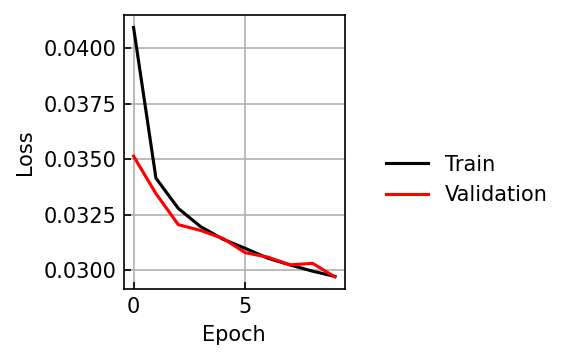

In [14]:
fig, ax = plt.subplots(1, 1, sharex=True, figsize=(2.5, 2.5))

train_loss, val_loss = model_stats
ax.plot(train_loss, color='black', label='Train')
ax.plot(val_loss, color='red', label='Validation')
ax.set(xlabel='Epoch', ylabel='Loss')

fig.legend(*ax.get_legend_handles_labels(), 
           loc='center left', bbox_to_anchor=[1, 0.5], framealpha=0)

plt.tight_layout()

### Inference

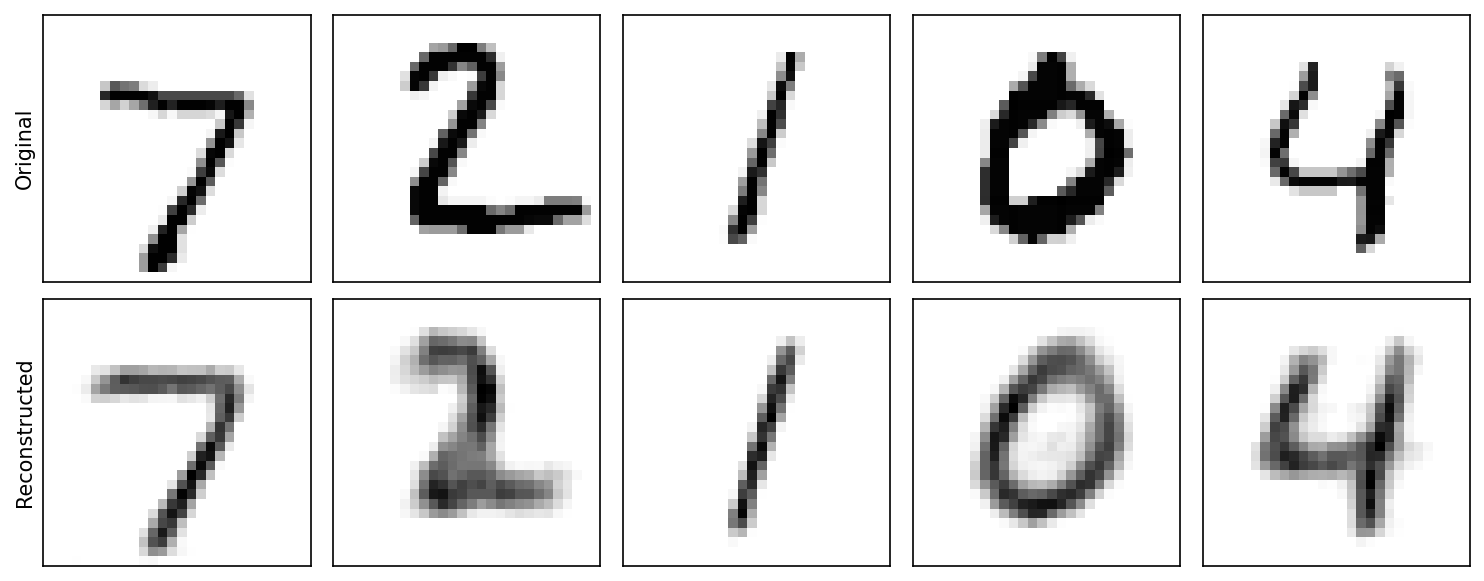

In [15]:
fig, ax = plt.subplots(2, 5, figsize=(10, 4), sharex=True, sharey=True)
for ii in range(5):
    xb, _ = mnist_test[ii]
    ax[0, ii].imshow(xb.squeeze().cpu().numpy(), cmap='Greys')
    with torch.no_grad():
        x_pred, z_pred = model(xb.to(device))
    ax[1, ii].imshow(x_pred.squeeze().cpu().numpy(), cmap='Greys')

ax[0,0].set_ylabel('Original')
ax[1,0].set_ylabel('Reconstructed')

for a in ax.flatten():
    a.set(xticks=[], yticks=[])
plt.tight_layout()

In [16]:
# Inference
model.eval()
test_loader = DataLoader(mnist_test, batch_size=128, shuffle=False)

y_true = []
z_pred = []

with torch.no_grad():
    for xb, yb in tqdm(test_loader,leave=False):
        xb = xb.to(device)
        xp, zp = model(xb)
        y_true.append(yb.cpu().numpy())
        z_pred.append(zp.cpu().numpy())

y_true = np.concatenate(y_true)
z_pred = np.concatenate(z_pred)

  0%|          | 0/79 [00:00<?, ?it/s]

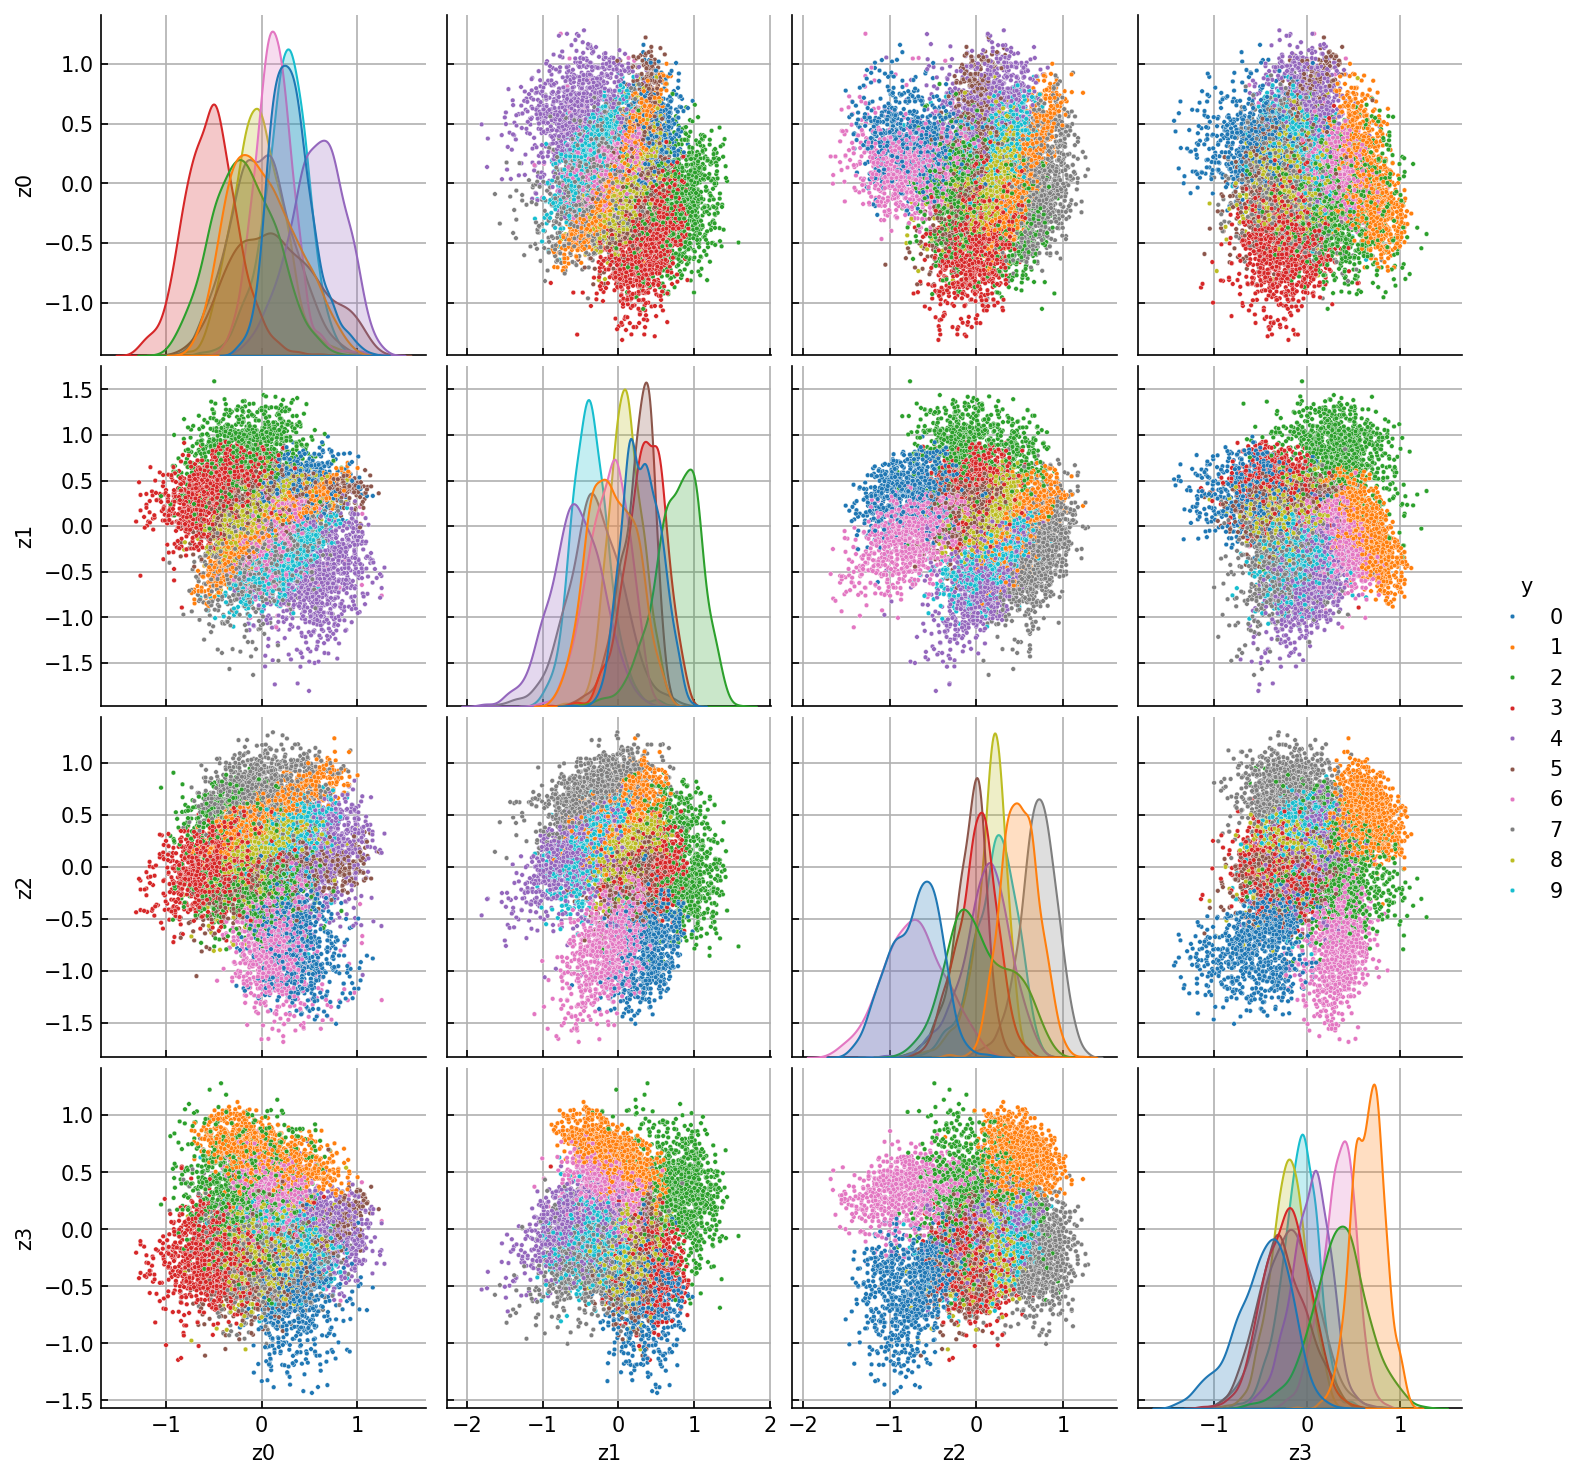

In [17]:
import seaborn as sns

df = pd.DataFrame({
    'z0': z_pred[:, 0],
    'z1': z_pred[:, 1],
    'z2': z_pred[:, 2],
    'z3': z_pred[:, 3],
    'y': y_true
})

sns.pairplot(df, hue='y', palette='tab10', plot_kws={'s': 5})

In [18]:
from sklearn.manifold import TSNE

viz = TSNE(n_components=2)
z_2d = viz.fit_transform(z_pred)

[Text(0.5, 0, 't-SNE 1'), Text(0, 0.5, 't-SNE 2')]

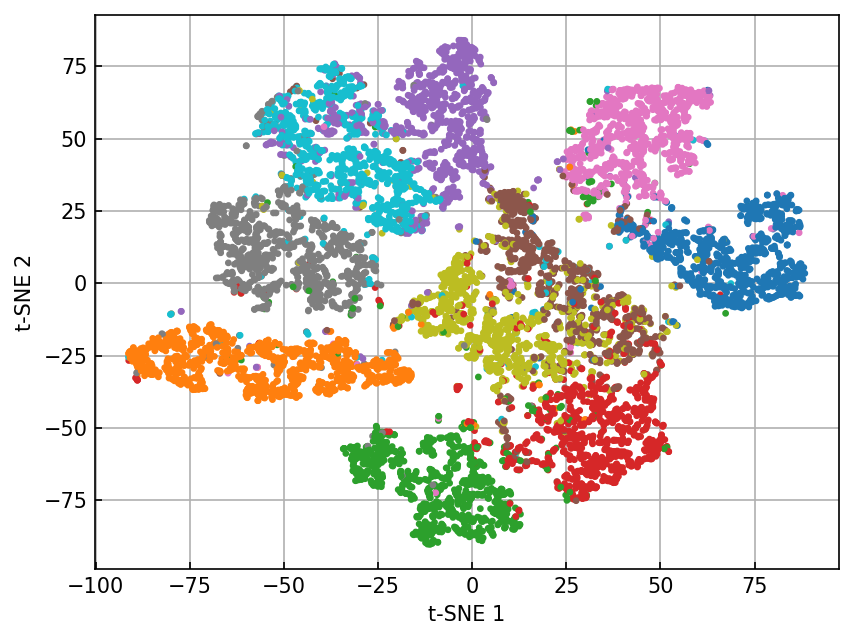

In [19]:
fig, ax = plt.subplots()
ax.scatter(
    z_2d[:, 0],
    z_2d[:, 1],
    c=y_true,
    cmap='tab10',
    s=5
)
ax.set(xlabel='t-SNE 1', ylabel='t-SNE 2')

## Supervised Learning with Representations (Deep Variational IB)

In [22]:
class SupervisedRepresentationCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding='same'),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 32, kernel_size=3, padding='same'),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.fc1 = nn.Linear(32*7*7, 4 * 2)

        # Everything above is p_{\theta} (z | x)
        # Everything below is q_{\phi} (y | x)
        self.fc2 = nn.Linear(4, 10)

    def forward(self, x):
        x = self.cnn(x)
        x = x.reshape([x.shape[0], -1])
        params = self.fc1(x)

        mu = params[..., 0:4]
        logvar = params[..., 4:8]

        # Sample from N(mu, sigma)
        # Reparameterization trick
        if self.training:
            noise = (0.5 * logvar).exp() * torch.randn_like(mu)
        else:
            noise = 0.

        z = mu + noise

        # Apply q_{\phi}
        y = self.fc2(z)
        return y, z, (mu, logvar)

In [23]:
from tqdm.notebook import tqdm, trange
from torch.utils.data import DataLoader

def augmented_loss(y_pred, y_true, mu, logvar, beta=1.):
    base_loss = F.cross_entropy(y_pred, y_true, reduction='sum')
    kld = -0.5 * torch.sum( 1 - mu*mu + logvar - logvar.exp())
    return (base_loss + kld * beta) / y_pred.shape[0]

def train_supervised_representations(model, loss_fn, optimizer, train_dataset, val_dataset, 
                                     batch_size=32, num_epochs=50, num_workers=2, beta=1, device=device):
    # Send model to correct hardware device
    model = model.to(device)

    # Create dataloaders for train/validation
    train_loader = DataLoader(train_dataset, batch_size=batch_size, num_workers=num_workers, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, num_workers=num_workers, shuffle=False)

    train_loss, train_acc = [], []
    val_loss, val_acc = [], []
    
    for epoch in range(num_epochs):
        train_loss_ = 0.
        train_acc_ = 0.
        model.train()
        for x, y, in tqdm(train_loader, leave=False):
            # Send x, y to GPU/TPU/etc.
            x = x.to(device)
            y = y.to(device)

            # Make a prediction, compute the loss
            y_pred, z_pred, params = model(x)
            loss = loss_fn(y_pred, y, *params, beta)

            # Backpropagate gradients, apply weight updates, reset gradients
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

            # Logging
            train_loss_ += loss.item() * x.shape[0]
            train_acc_  += (torch.argmax(y_pred, dim=1) == y).float().sum().item()

        train_loss.append(train_loss_ / len(train_dataset))
        train_acc.append(train_acc_ / len(train_dataset))

        val_loss_ = 0.
        val_acc_ = 0.
        model.eval()
        with torch.no_grad():
            for x, y, in tqdm(val_loader, leave=False):
                # Send x, y to GPU/TPU/etc.
                x = x.to(device)
                y = y.to(device)
    
                # Make a prediction, compute the loss
                y_pred, z_pred, params = model(x)
                loss = loss_fn(y_pred, y, *params, beta)
                
                # Logging
                val_loss_ += loss.item() * x.shape[0]
                val_acc_  += (torch.argmax(y_pred, dim=1) == y).float().sum().item()

            val_loss.append(val_loss_ / len(val_dataset))
            val_acc.append(val_acc_ / len(val_dataset))

        print(f'Epoch {epoch+1} | '
              f'Train loss { train_loss[-1]:.3f} | '
              f'Train acc { train_acc[-1]:.3f} | '
              f'Val loss { val_loss[-1]:.3f} | '
              f'Val acc { val_acc[-1]:.3f}'
        )

    return model, (train_loss, train_acc, val_loss, val_acc)

model = SupervisedRepresentationCNN()
loss = augmented_loss
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
model, model_stats = train_supervised_representations(
    model, 
    loss, 
    optimizer, 
    mnist_train, 
    mnist_val, 
    num_epochs=10,
    batch_size=64,
    num_workers=4,
    beta=1e-2
)

  0%|          | 0/750 [00:00<?, ?it/s]

  0%|          | 0/188 [00:00<?, ?it/s]

Epoch 1 | Train loss 1.732 | Train acc 0.447 | Val loss 1.359 | Val acc 0.615


  0%|          | 0/750 [00:00<?, ?it/s]

  0%|          | 0/188 [00:00<?, ?it/s]

Epoch 2 | Train loss 1.221 | Train acc 0.685 | Val loss 1.087 | Val acc 0.737


... (20 outputs left out)

Epoch 9 | Train loss 0.504 | Train acc 0.940 | Val loss 0.479 | Val acc 0.947


  0%|          | 0/750 [00:00<?, ?it/s]

  0%|          | 0/188 [00:00<?, ?it/s]

Epoch 10 | Train loss 0.473 | Train acc 0.947 | Val loss 0.457 | Val acc 0.948


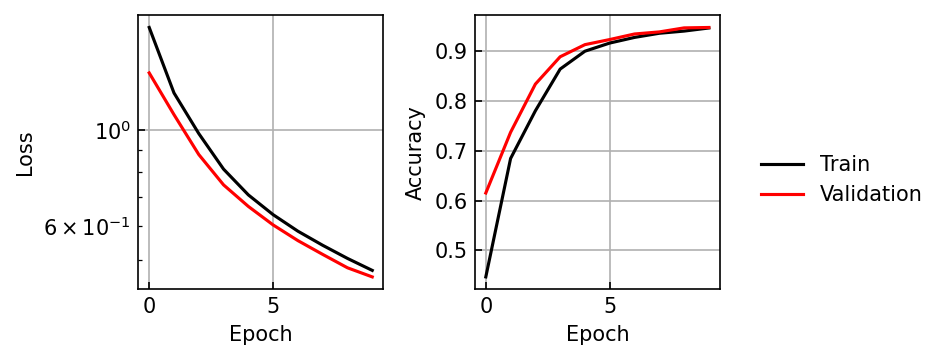

In [24]:
fig, ax = plt.subplots(1, 2, sharex=True, figsize=(5, 2.5))

train_loss, train_acc, val_loss, val_acc = model_stats
ax[0].plot(train_loss, color='black', label='Train')
ax[0].plot(val_loss, color='red', label='Validation')
ax[0].set(xlabel='Epoch', ylabel='Loss', yscale='log')

ax[1].plot(train_acc, color='black', label='Train')
ax[1].plot(val_acc, color='red', label='Validation')
ax[1].set(xlabel='Epoch', ylabel='Accuracy')

fig.legend(*ax[1].get_legend_handles_labels(), 
           loc='center left', bbox_to_anchor=[1, 0.5], framealpha=0)

plt.tight_layout()

### Inference

In [25]:
from sklearn.metrics import accuracy_score
# Inference
model.eval()
test_loader = DataLoader(mnist_test, batch_size=128, shuffle=False)

y_true = []
y_pred = []
z_pred = []

with torch.no_grad():
    test_correct_ = 0.
    for xb, yb in tqdm(test_loader,leave=False):
        xb = xb.to(device)
        yb = yb.to(device)
        yp, zp, params = model(xb)

        y_true.append(yb.cpu().numpy())
        y_pred.append(yp.cpu().numpy())
        z_pred.append(zp.cpu().numpy())

y_true = np.concatenate(y_true)
y_pred = np.concatenate(y_pred)
z_pred = np.concatenate(z_pred)

test_acc = accuracy_score(y_true, np.argmax(y_pred, axis=1))
print(f"Test accuracy: {test_acc:.3f}")

  0%|          | 0/79 [00:00<?, ?it/s]

Test accuracy: 0.957


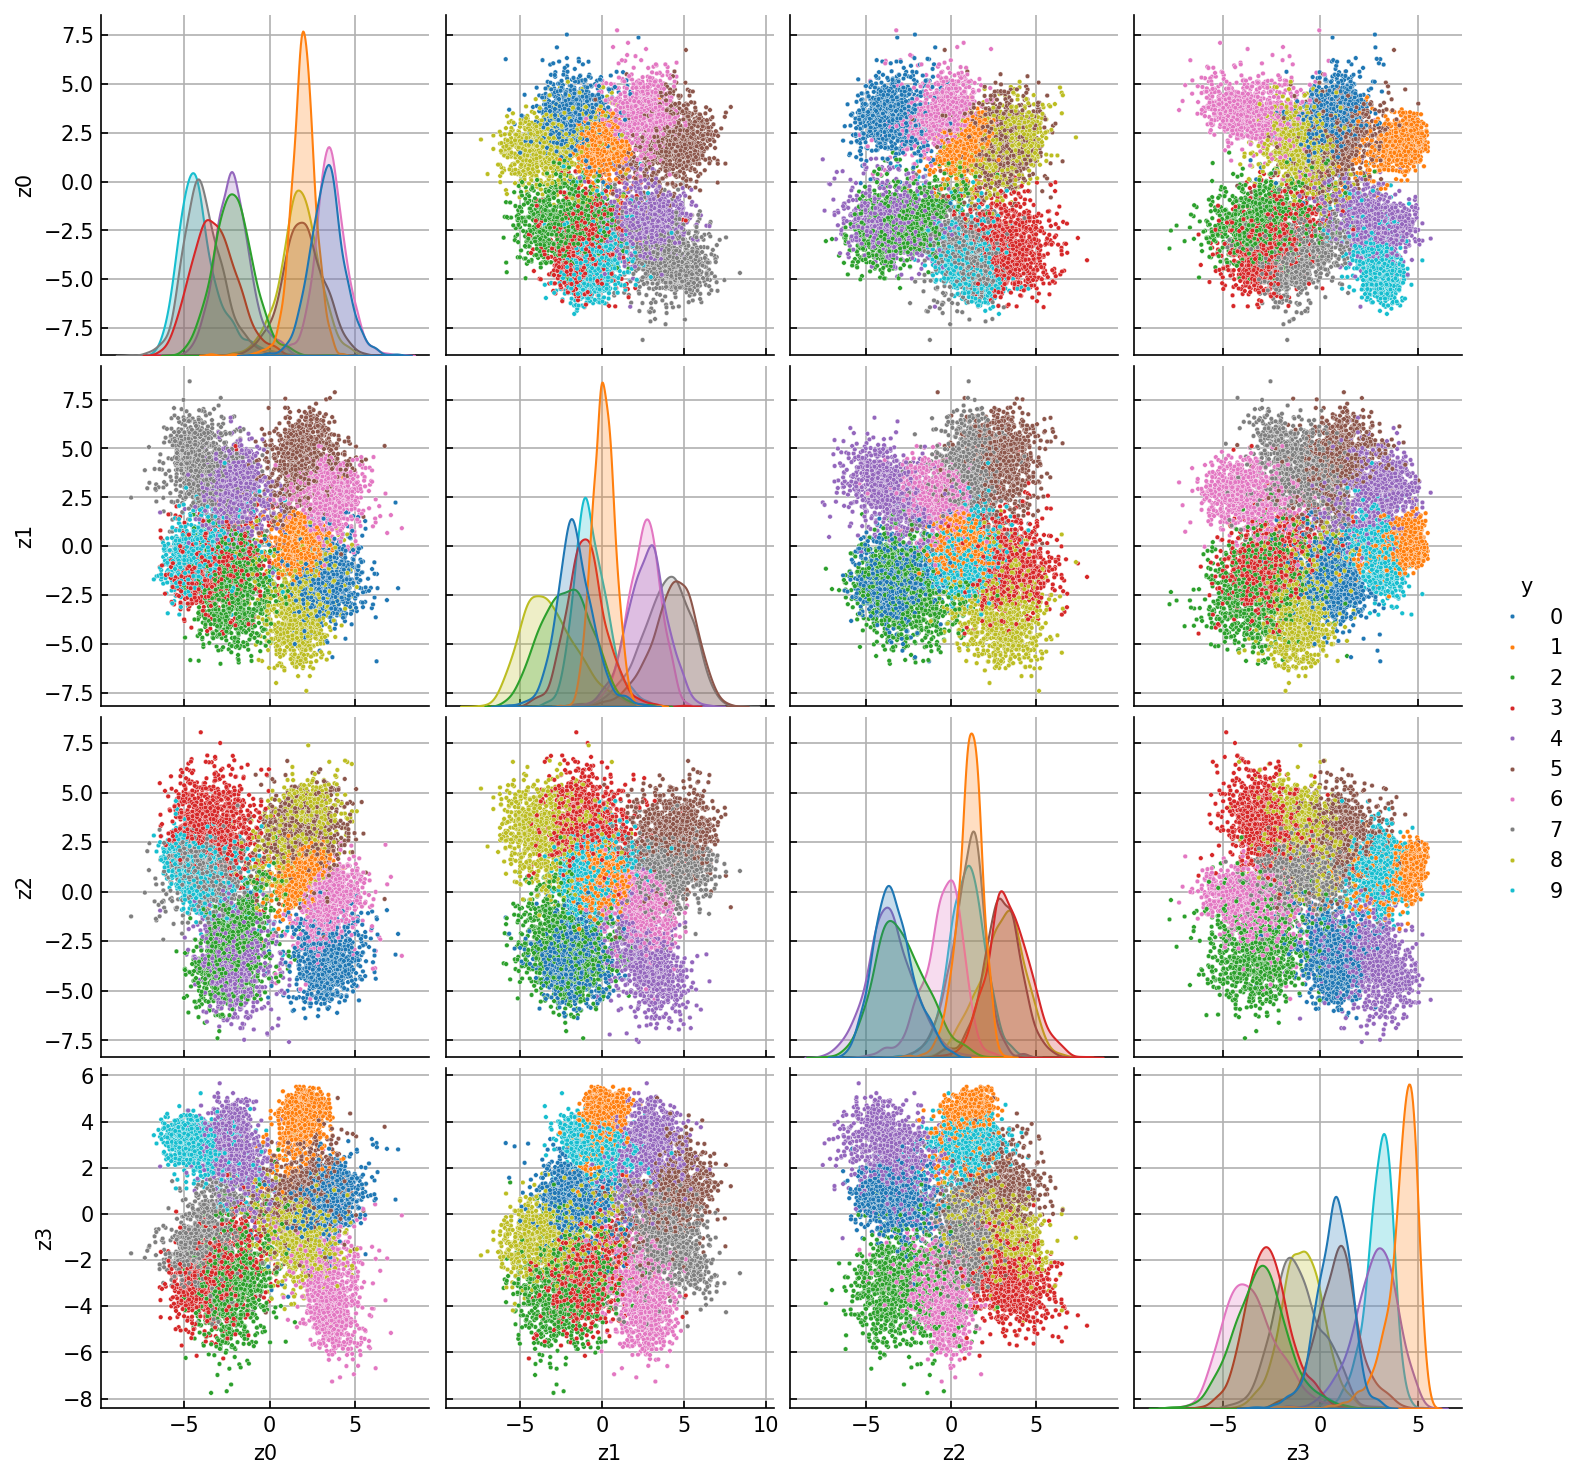

In [26]:
import seaborn as sns

df = pd.DataFrame({
    'z0': z_pred[:, 0],
    'z1': z_pred[:, 1],
    'z2': z_pred[:, 2],
    'z3': z_pred[:, 3],
    'y': y_true
})

sns.pairplot(df, hue='y', palette='tab10', plot_kws={'s': 5})

[Text(0.5, 0, 't-SNE 1'), Text(0, 0.5, 't-SNE 2')]

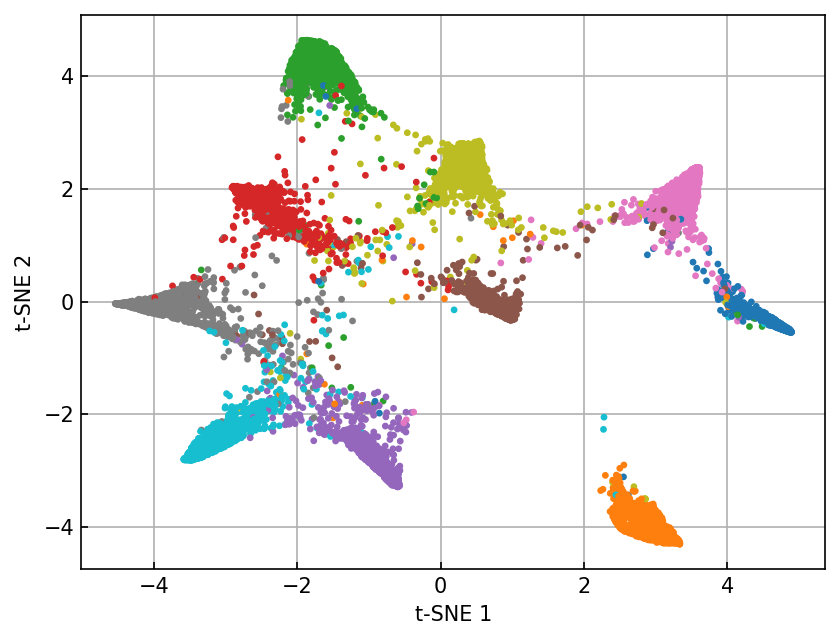

In [27]:
from sklearn.manifold import TSNE

viz = TSNE(n_components=2, n_iter=250)
z_2d = viz.fit_transform(z_pred)

fig, ax = plt.subplots()
ax.scatter(
    z_2d[:, 0],
    z_2d[:, 1],
    c=y_true,
    cmap='tab10',
    s=5
)
ax.set(xlabel='t-SNE 1', ylabel='t-SNE 2')